# BBTD for covariance images (ADMM)

In a covariance image each pixel holds a K × K covariance matrix, so the data form a
fourth-order tensor of shape (rows, columns, K, K). The constrained **BBTD** model writes it
as a sum of terms *non-negative spatial map × covariance matrix*, with spatial maps of
rank L1 and covariance matrices Cᵣ Cᵣᴴ of rank L2 (see [BBTD](../models/bbtd.md)).

The ADMM solver keeps the maps non-negative and enforces D = C*, so that every second
block is a covariance matrix.

![A fourth-order covariance image written as a sum of R spatial maps, each times one covariance matrix](../images/model_bbtd.png)

## The data

20 × 25 pixels with 4 × 4 covariance matrices, R = 3 terms, spatial maps of rank L1 = 3
built from random non-negative factors, and covariance matrices of rank L2 = 2.

In [1]:
import numpy as np

from pybbtd import BBTD
from pybbtd.bbtd import factors_to_tensor
from pybbtd.btd import spatial_maps
from pybbtd.visualization import plot_error

np.random.seed(0)
R, L1, L2 = 3, 3, 2
model = BBTD((20, 25, 4, 4), R=R, L1=L1, L2=L2)

A0 = np.random.rand(20, L1 * R)
B0 = np.random.rand(25, L1 * R)
C0 = np.random.randn(4, L2 * R) + 1j * np.random.randn(4, L2 * R)
phi, psi = model.get_constraint_matrices()
T = factors_to_tensor(A0, B0, C0, C0.conj(), phi, psi)
T.shape

(20, 25, 4, 4)

## Fit the model

In [2]:
model.check_uniqueness()

True

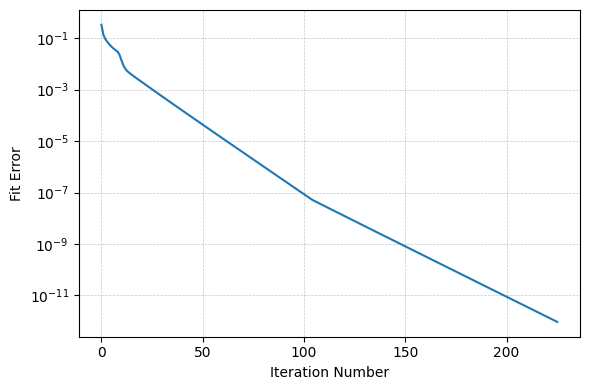

In [3]:
model.fit(
    T, algorithm="ADMM", init="kmeans", max_iter=1000, rel_tol=1e-10, abs_tol=1e-12
)
plot_error(model.fit_error)

## Check the result

The second blocks satisfy D = C* exactly, the spatial maps are non-negative, and the
relative error is small:

In [4]:
A, B, C, D = model.factors
print("D = C*:", np.array_equal(D, C.conj()))
print("maps non-negative:", spatial_maps(A, B, L1).min() >= 0)
print("relative error:", np.linalg.norm(model.tensor - T) / np.linalg.norm(T))

D = C*: True
maps non-negative: True
relative error: 9.417483578242967e-13
